# Chance

In [1]:
# datascience
from datascience import *
%matplotlib inline

import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

import numpy as np
import warnings

In [2]:
# polars
import polars as pl
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plots

def _append(base, extra):
    """Append a value or a Series onto a Series."""
    extra_s = extra if isinstance(extra, pl.Series) else pl.Series([extra])
    if base.len() == 0:
        return extra_s
    if base.dtype != extra_s.dtype:
        try:
            extra_s = extra_s.cast(base.dtype, strict=False)
        except Exception:
            base = base.cast(extra_s.dtype, strict=False)
    return pl.concat([base, extra_s])


## Simulation Review

In [3]:
# datascience
coin = make_array('heads', 'tails')

In [4]:
# polars
coin_pl = pl.Series("values", ['heads', 'tails'])

In [5]:
# datascience
np.random.choice(coin) # assume fair coin

'heads'

In [6]:
# polars
(coin_pl).sample(1).item() # assume fair coin

'tails'

In [7]:
# datascience
tosses = np.random.choice(coin, 10)
tosses

array(['heads', 'tails', 'heads', 'tails', 'tails', 'heads', 'heads',
       'heads', 'tails', 'tails'],
      dtype='<U5')

In [8]:
# polars
tosses_pl = (coin_pl).sample(10, with_replacement=True)
tosses_pl

values
str
"""heads"""
"""tails"""
"""tails"""
"""heads"""
"""heads"""
"""heads"""
"""heads"""
"""heads"""
"""tails"""


In [9]:
# datascience
sum(tosses == 'heads')

5

In [10]:
# polars
sum(tosses_pl == 'heads')

6

In [11]:
# datascience
sum(np.random.choice(coin, 10) == 'heads')

5

In [12]:
# polars
sum((coin_pl).sample(10, with_replacement=True) == 'heads')

7

In [13]:
# datascience
# 1. define function that simulates one outcome of the experiment
# Simulate one outcome based on 100 tosses.

def heads_in_100_tosses():
    return sum(np.random.choice(coin, 100) == 'heads')

In [14]:
# polars
# 1. define function that simulates one outcome of the experiment
# Simulate one outcome based on 100 tosses.

def heads_in_100_tosses_pl():
    return sum((coin_pl).sample(100, with_replacement=True) == 'heads')

What if you wanted to simulate the experiment 10,000 times?

In [15]:
# datascience
# 2. record outcomes of repeating the experiment many times
# Decide how many times you want to repeat the experiment
num_simulations = 10000

# Simulate that many outcomes
outcomes = make_array()
for i in np.arange(num_simulations):
    heads_in_100_tosses()
    
outcomes

array([], dtype=float64)

In [16]:
# polars
# 2. record outcomes of repeating the experiment many times
# Decide how many times you want to repeat the experiment
num_simulations_pl = 10000

# Simulate that many outcomes
outcomes_pl = pl.Series("values", [], dtype=pl.Float64)
for i in pl.int_range(num_simulations_pl, eager=True):
    heads_in_100_tosses_pl()
    
outcomes_pl

values
f64


**DISCUSS**: What is wrong with the above simulation?

In [17]:
# datascience
# TODO: the fixed version

# Decide how many times you want to repeat the experiment
num_simulations = 10000

# Simulate that many outcomes
outcomes = make_array()
for i in np.arange(num_simulations):
    outcomes = np.append(outcomes, heads_in_100_tosses())
    
outcomes

array([ 50.,  47.,  54., ...,  53.,  51.,  50.])

In [18]:
# polars
# TODO: the fixed version

# Decide how many times you want to repeat the experiment
num_simulations_pl = 10000

# Simulate that many outcomes
outcomes_pl = []
for i in pl.int_range(num_simulations_pl, eager=True):
    outcomes_pl.append(heads_in_100_tosses_pl())
    
outcomes_pl = pl.Series("values", outcomes_pl)
outcomes_pl

values
i64
42
51
45
37
56
…
52
45
53


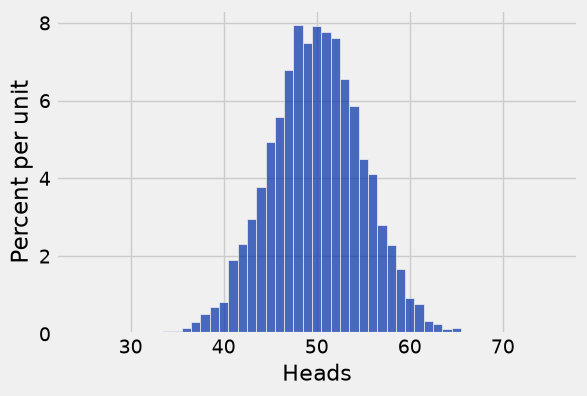

In [19]:
# datascience
heads = Table().with_column('Heads', outcomes)
heads.hist(bins = np.arange(24.5, 76.5))

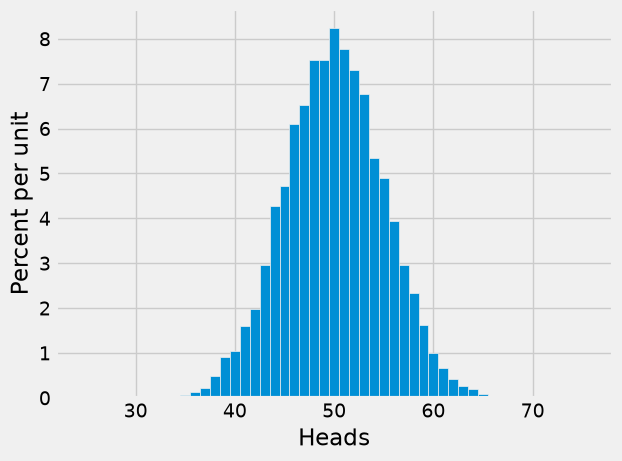

In [20]:
# polars
# matplotlib
heads_pl = pl.DataFrame({'Heads': outcomes_pl})
_df = heads_pl
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(24.5, 75.5, 52, closed="both", eager=True)))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(24.5, 75.5, 52, closed="both", eager=True)))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

**DISCUSS**:
1. In one sentence, what is this chart showing?
2. Is a 50/50 split likely?

## Chance?

### Probability Question

3 cards: A, K, Q

Draw two cards at random without replacement.

What is the chance of a Queen followed by a King?

First Solution:


Alternative Solution:


### Another Question

Same setting as above.

What is the chance that one of the cards drawn is the King and the other is the Queen?

First Solution:


Alternative Solution:


### Complement Rule

Done on slide.

<br/><br/><br/><br/><br/><br/><br/>

## The Monty Hall Problem ###

In [21]:
# datascience
goats = make_array('🐐 #1', '🐐 #2')
doors = make_array('🐐 #1', '🐐 #2', '🚗')
doors

array(['🐐 #1', '🐐 #2', '🚗'],
      dtype='<U4')

In [22]:
# polars
goats_pl = pl.Series("values", ['🐐 #1', '🐐 #2'])
doors_pl = pl.Series("values", ['🐐 #1', '🐐 #2', '🚗'])
doors_pl

values
str
"""🐐 #1"""
"""🐐 #2"""
"""🚗"""


In [23]:
def other_goat(x):
    if x == '🐐 #1':
        return '🐐 #2'
    elif x == '🐐 #2':
        return '🐐 #1'

In [24]:
# datascience
make_array(other_goat('🐐 #1'), other_goat('🐐 #2'))

array(['🐐 #2', '🐐 #1'],
      dtype='<U4')

In [25]:
# polars
pl.Series("values", [other_goat('🐐 #1'), other_goat('🐐 #2')])

values
str
"""🐐 #2"""
"""🐐 #1"""


In [26]:
# datascience
def monty_hall():
    """Return 
    [contestant's guess, what Monty reveals, what remains behind the other door]"""
    
    contestant_choice = np.random.choice(doors)
    
    if contestant_choice == '🐐 #1':
        monty_choice = '🐐 #2'
        remaining_choice = '🚗'
    
    if contestant_choice == '🐐 #2':
        monty_choice = '🐐 #1'
        remaining_choice = '🚗'
    
    if contestant_choice == '🚗':
        monty_choice = np.random.choice(goats)
        remaining_choice = other_goat(monty_choice)
        
    return make_array(contestant_choice, monty_choice, remaining_choice)

In [27]:
# polars
def monty_hall_pl():
    """Return 
    [contestant's guess, what Monty reveals, what remains behind the other door]"""
    
    contestant_choice = (doors_pl).sample(1).item()
    
    if contestant_choice == '🐐 #1':
        monty_choice = '🐐 #2'
        remaining_choice = '🚗'
    
    if contestant_choice == '🐐 #2':
        monty_choice = '🐐 #1'
        remaining_choice = '🚗'
    
    if contestant_choice == '🚗':
        monty_choice = (goats_pl).sample(1).item()
        remaining_choice = other_goat(monty_choice)
        
    return pl.Series("values", [contestant_choice, monty_choice, remaining_choice])

In [28]:
# datascience
monty_hall()

array(['🐐 #2', '🐐 #1', '🚗'],
      dtype='<U4')

In [29]:
# polars
monty_hall_pl()

values
str
"""🚗"""
"""🐐 #2"""
"""🐐 #1"""


In [30]:
# datascience
results = Table(make_array('Guess', 'Revealed', 'Remaining'))

for i in np.arange(10000):
    results.append(monty_hall())

In [31]:
# polars
results_pl = pl.DataFrame(schema={'Guess': pl.String, 'Revealed': pl.String, 'Remaining': pl.String})

_rows_results = []
for i in pl.int_range(10000, eager=True):
    _rows_results.append(list(monty_hall_pl()))
results_pl = pl.DataFrame(_rows_results, schema=results_pl.schema, orient="row")

In [32]:
# datascience
results.show(5)

Guess,Revealed,Remaining
🐐 #1,🐐 #2,🚗
🚗,🐐 #2,🐐 #1
🐐 #1,🐐 #2,🚗
🐐 #1,🐐 #2,🚗
🐐 #2,🐐 #1,🚗


In [33]:
# polars
results_pl.head(5)

Guess,Revealed,Remaining
str,str,str
"""🐐 #1""","""🐐 #2""","""🚗"""
"""🚗""","""🐐 #1""","""🐐 #2"""
"""🐐 #2""","""🐐 #1""","""🚗"""
"""🚗""","""🐐 #1""","""🐐 #2"""
"""🚗""","""🐐 #2""","""🐐 #1"""


In [34]:
# datascience
original_choice = results.group('Guess')
original_choice

Guess,count
🐐 #1,3349
🐐 #2,3347
🚗,3304


In [35]:
# polars
original_choice_pl = (lambda _df, _k='Guess': _df.group_by(_k).len(name='count').sort(_k))(results_pl)
original_choice_pl

Guess,count
str,u32
"""🐐 #1""",3271
"""🐐 #2""",3358
"""🚗""",3371


In [36]:
# datascience
remaining_door = results.group('Remaining')
remaining_door

Remaining,count
🐐 #1,1628
🐐 #2,1676
🚗,6696


In [37]:
# polars
remaining_door_pl = (lambda _df, _k='Remaining': _df.group_by(_k).len(name='count').sort(_k))(results_pl)
remaining_door_pl

Remaining,count
str,u32
"""🐐 #1""",1716
"""🐐 #2""",1655
"""🚗""",6629


In [38]:
# datascience
# Collect all the results

all_results = Table().with_columns('Emoji', doors, 'Item', make_array('goat 1', 'goat 2', 'car'))
all_results = all_results.join('Emoji', original_choice, 'Guess').relabeled('count', 'Original Door')
all_results = all_results.join('Emoji', remaining_door, 'Remaining').relabeled('count', 'Remaining Door')
all_results

Emoji,Item,Original Door,Remaining Door
🐐 #1,goat 1,3349,1628
🐐 #2,goat 2,3347,1676
🚗,car,3304,6696


In [39]:
# polars
# Collect all the results

all_results_pl = pl.DataFrame({'Emoji': doors_pl, 'Item': pl.Series("values", ['goat 1', 'goat 2', 'car'])})
all_results_pl = (lambda _df: _df.sort('Emoji').join((original_choice_pl).sort('Guess'), left_on='Emoji', right_on='Guess'))(all_results_pl).rename({'count': 'Original Door'})
all_results_pl = (lambda _df: _df.sort('Emoji').join((remaining_door_pl).sort('Remaining'), left_on='Emoji', right_on='Remaining'))(all_results_pl).rename({'count': 'Remaining Door'})
all_results_pl

Emoji,Item,Original Door,Remaining Door
str,str,u32,u32
"""🐐 #1""","""goat 1""",3271,1716
"""🐐 #2""","""goat 2""",3358,1655
"""🚗""","""car""",3371,6629


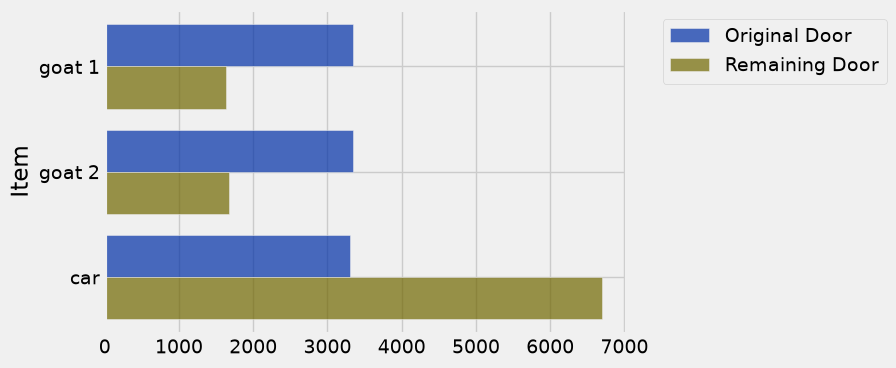

In [40]:
# datascience
# how likely is it that the item is behind each door?
all_results = all_results.drop('Emoji')
all_results.barh('Item')

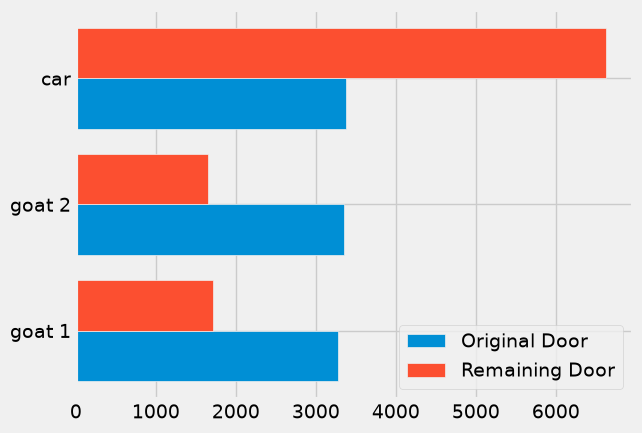

In [41]:
# polars
# matplotlib
# how likely is it that the item is behind each door?
all_results_pl = all_results_pl.drop('Emoji')
_df = all_results_pl
_cat = 'Item'
_vals = [c for c in _df.columns if c != _cat and _df[c].dtype.is_numeric()]
if len(_vals) == 1:
    plots.barh(_df.get_column(_cat).to_list(), _df.get_column(_vals[0]).to_list())
    plots.xlabel(_vals[0])
else:
    _n = len(_vals)
    _y = list(range(_df.height))
    _h = 0.8 / _n
    for _i, _c in enumerate(_vals):
        plots.barh([y + _i * _h for y in _y], _df.get_column(_c).to_list(), height=_h, label=_c)
    plots.yticks([y + _h * (_n - 1) / 2 for y in _y], _df.get_column(_cat).to_list())
    plots.legend()